### Import necessary packages

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os

### Define directories

In [ ]:
saved_domain_directory = r".\Template_Domains-with-Neighbourhoods"

save_distances_directory = r".\Template_Distances-Analysis"
if not os.path.exists(save_distances_directory):
    os.makedirs(save_distances_directory)

### Load in saved directories

In [3]:
saved_domains = os.listdir(saved_domain_directory)

domains = []

for s_domain in saved_domains:
    domain = ms.io.load_domain(os.path.join(saved_domain_directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_1.csv
Number of objects: 102476
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_2.csv
Number of objects: 415262
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_3.csv
Number of objects: 229276
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Di

### Cell type - cell type minimum distances

#### Please note: The distances are not symetric. The shortest distance between cell 1 of class A and any cell of class B will not be the same as cell 2 of class B to any cell of class A.

##### Can also repeat by doing for example neighbourhood - neighbourhood, just replace class1 and class2 with the neighbourhoods of interest and adjust the queries to look for the label name that is linked to the neighbourhoods

In [4]:
# Define classes of interest
class1 = ["CD8", "CD8_Other", "PDPN_CD8", "PDPN_CD8_Other"]
class2 = ['FAP' ,'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN','FAP_PDPN_PDGFRa' ,'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA']

### Option 1: Distance between cells in class1 to any celltype in class2

In [6]:
for domain in domains:
    class_A = class1
    class_B = class2

    distances_data = {}

    object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_A))
    object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_B))
    try:
        min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_A, object_indices_B) # Measures distance from A to B
        min_dist_A_B = min_dist_tuple_A_B[0]

        distances_data[domain.name] = min_dist_A_B

        df = pd.DataFrame(data=distances_data[domain.name])
                
        folder_name = class_A[0]+"_to_"+class_B[0]
        path = os.path.join(save_distances_directory+"/all_CD8_to_all_FAP", folder_name)
        
        if not os.path.exists(path):
            os.makedirs(path)

        df.to_csv(os.path.join(path, domain.name), header=False, index=False)

    except:
        continue

### Option 1: Distances between cells in class1 to each celltype in class2

In [7]:
for domain in domains:
    class_A = class1
    for i in range(len(class2)):
        class_B = class2[i]

        distances_data = {}

        object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_A))
        object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'is', [class_B]))

        try:
            min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_A, object_indices_B)
            min_dist_A_B = min_dist_tuple_A_B[0]

            distances_data[domain.name] = min_dist_A_B

            df = pd.DataFrame(data=distances_data[domain.name])
                
            folder_name = class_A[0]+"_to_"+class_B
            path = os.path.join(save_distances_directory+"/all_CD8_each_FAP", folder_name)
            if not os.path.exists(path):
                os.makedirs(path)

            df.to_csv(os.path.join(path, domain.name), header=False, index=False)

        except:
            continue

### Plot the distances

[Text(0, 0.0, '0'), Text(0, 0.007, '7'), Text(0, 0.014, '14')]

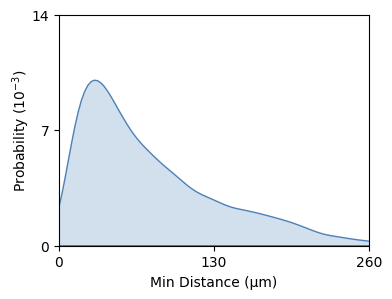

In [9]:

path_for_distance_file = r"Template_Distances-Analysis\all_CD8_each_FAP\CD8_to_FAP_PDGFRa\test_data_1.csv"

min_dist_A_B = np.loadtxt(path_for_distance_file, dtype=int)

# Plot the distribution of minimum distances
fig, ax = plt.subplots(figsize=(4, 3))

sns.kdeplot(x=min_dist_A_B, fill=True, ax=ax, color=[76/255, 129/255, 182/255, 1])

ax.set_xlabel('Min Distance (µm)')
ax.set_ylabel('Probability ($10^{-3}$)', labelpad=0)
ax.set_xlim([0, 260])
ax.set_ylim([0, 0.014])
ax.set_yticks([0, 0.007, 0.014])
ax.set_xticks([0, 130, 260])
ax.set_yticklabels([0, 7, 14])